## Libraries

In [116]:
import random
import numpy as np
import torch
from pathlib import Path
import kagglehub
from dataclasses import dataclass, replace, asdict
import json
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.utils as vutils
from PIL import Image
import matplotlib.pyplot as plt
import time
import torch.nn as nn
import torch.optim as optim
import shutil

## Config Cell

In [117]:
@dataclass(frozen= True)
class Config:
    # Reproducibility
    SEED: int = 42

    # Dataset
    DATASET: str = "jessicali9530/celeba-dataset"
    EXPECTED_IMAGES: int = 202_599
    DATA_DIR: Path = (Path.cwd().parent / "Data" / "celeba").resolve()

    # Run / output paths
    RUN_NAME: str = "baseline"
    ARTIFACT_ROOT: Path = (Path.cwd() / "artifacts" / "GAN").resolve()

    # Data Pipeline
    IMAGE_SIZE: int = 64
    CHANNELS: int = 3
    BATCH_SIZE: int = 128
    NUM_WORKERS: int = 4
    CROP_SIZE: int = 148

    # Model
    LATENT_DIM: int = 100
    G_FEATURES: int = 64
    D_FEATURES: int = 64

    # Optimizer / init 
    LR: float = 2e-4
    BETA1: float = 0.5
    BETA2: float = 0.999
    INIT_STD: float = 0.02

    # Training
    EPOCHS: int = 25
    LOG_EVERY: int = 100

    # --- Monitoring ---
    N_FIXED_SAMPLES: int = 64
    CHECKPOINT_EVERY: int = 5
    
    def __post_init__(self):
        assert self.IMAGE_SIZE == 64

    @property
    def RUN_DIR(self) -> Path:
        return self.ARTIFACT_ROOT / self.RUN_NAME

    @property
    def CKPT_DIR(self) -> Path:
       return self.RUN_DIR / "checkpoints" 

    @property
    def SAMPLE_DIR(self) -> Path:
        return self.RUN_DIR / "samples"

    @property
    def PLOT_DIR(self) -> Path:
        return self.RUN_DIR / "plots"

    def make_dirs(self):
        for d in (self.RUN_DIR, self.CKPT_DIR,self.SAMPLE_DIR, self.PLOT_DIR):
            d.mkdir(parents = True, exist_ok = True)

    def save(self):
        path = self.RUN_DIR / "config.json"
        path.write_text(json.dumps(asdict(self), indent = 2, default = str))
        return path

cfg = Config()
cfg.make_dirs()
cfg.save()
print(f"Run: {cfg.RUN_NAME} -> {cfg.RUN_DIR}")


Run: baseline -> /home/harsh/Work/Notebooks/Projects/Notebooks/artifacts/GAN/baseline


In [118]:
# Checks For GPU
seed = cfg.SEED
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)   # safe to call even without a GPU

# Falls back to CPU so other people can still run the notebook
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA (built with):", torch.version.cuda)
    print(f"VRAM free/total: {free / 1e9:.1f} / {total / 1e9:.1f} GB")

PyTorch: 2.14.1+cu130
Device: cuda
GPU: NVIDIA GeForce RTX 3060
CUDA (built with): 13.0
VRAM free/total: 11.0 / 12.9 GB


## Data 

In [119]:
# Relative to the notebook (Projects/Notebooks), so it works on any machine
data = cfg.DATA_DIR
image_count = cfg.EXPECTED_IMAGES

data.mkdir(parents=True, exist_ok=True)

def count_jpgs(root):
    return sum(1 for _ in root.rglob("*.jpg"))

existing = count_jpgs(data)

if existing >= image_count:
    print(f"Dataset already present ({existing:,} images). Skipping download.")
else:
    print(f"Found {existing:,} images, expected {image_count:,}. Downloading...")
    kagglehub.dataset_download(
        cfg.DATASET,
        output_dir=str(data),
        force_download=existing > 0,   # re-fetch only if a partial copy exists
    )

# Locate the folder that actually holds the JPEGs (the zip may nest it twice)
first = next(data.rglob("*.jpg"), None)
if first is None:
    raise FileNotFoundError(f"No JPEGs found under {data}. Download failed.")

IMG_DIR = first.parent
n_images = sum(1 for _ in IMG_DIR.glob("*.jpg"))
if n_images < image_count:
    raise RuntimeError(f"Only {n_images:,} images in {IMG_DIR}. Delete {data} and rerun.")

print(f"Ready: {n_images:,} images in {IMG_DIR}")


Dataset already present (202,599 images). Skipping download.
Ready: 202,599 images in /home/harsh/Work/Notebooks/Projects/Data/celeba/img_align_celeba/img_align_celeba


## Pipeline

In [120]:
class CelebADataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.paths = sorted(Path(img_dir).glob("*.jpg"))
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB") 
        return self.transform(img) if self.transform else img

transform = transforms.Compose([
    transforms.CenterCrop(cfg.CROP_SIZE),
    transforms.Resize((cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * cfg.CHANNELS, [0.5] * cfg.CHANNELS),
])

dataset = CelebADataset(IMG_DIR, transform)

loader = DataLoader(
    dataset,
    batch_size= cfg.BATCH_SIZE,
    shuffle= True,
    drop_last= True,
    num_workers= cfg.NUM_WORKERS,
    pin_memory= True,
    persistent_workers= cfg.NUM_WORKERS > 0,
)

print(f"Images: {len(dataset):,} | Batches/epoch: {len(loader):,}")

Images: 202,599 | Batches/epoch: 1,582


## Model Generator

In [121]:
class Generator(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        nz, f, nc = cfg.LATENT_DIM, cfg.G_FEATURES, cfg.CHANNELS
        self.nz = nz
        self.net = nn.Sequential(
            # [B, nz, 1, 1] -> [B, 8f, 4, 4]
            nn.ConvTranspose2d(nz, f * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(f * 8), nn.ReLU(True),
            # -> [B, 4f, 8, 8]
            nn.ConvTranspose2d(f * 8, f * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(f * 4), nn.ReLU(True),
            # -> [B, 2f, 16, 16]
            nn.ConvTranspose2d(f * 4, f * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(f * 2), nn.ReLU(True),
            # -> [B, f, 32, 32]
            nn.ConvTranspose2d(f * 2, f, 4, 2, 1, bias=False),
            nn.BatchNorm2d(f), nn.ReLU(True),
            # -> [B, nc, 64, 64], values in [-1, 1]
            nn.ConvTranspose2d(f, nc, 4, 2, 1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z.view(z.size(0), self.nz, 1, 1))
        

## Discriminator

In [122]:
class Discriminator(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        nc, f = cfg.CHANNELS, cfg.D_FEATURES
        self.net = nn.Sequential(
            nn.Conv2d(nc, f, 4, 2, 1, bias= False),
            nn.LeakyReLU(0.2, inplace= True),

            nn.Conv2d(f, f * 2, 4, 2, 1, bias= False),
            nn.BatchNorm2d(f*2), nn.LeakyReLU(0.2, inplace= True),

            nn.Conv2d(f*2, f*4, 4, 2, 1, bias= False),
            nn.BatchNorm2d(f*4), nn.LeakyReLU(0.2, inplace= True),

            nn.Conv2d(f*4, f*8, 4, 2, 1, bias= False),
            nn.BatchNorm2d(f*8), nn.LeakyReLU(0.2, inplace= True),

            nn.Conv2d(f*8, 1, 4, 1, 0, bias= False)
        )

    def forward(self, x):
        out = self.net(x)
        assert out.shape[1:] == (1, 1, 1), f"Unexpected D output: {tuple(out.shape)}"
        return out.view(-1)

## Optimizer Cell

In [123]:
def weights_init(m):
    name = m.__class__.__name__
    if "Conv" in name:
        nn.init.normal_(m.weight, 0.0, cfg.INIT_STD)
    elif "BatchNorm" in name:
        nn.init.normal_(m.weight, 1.0, cfg.INIT_STD)
        nn.init.zeros_(m.bias)

def build(cfg):
    netG = Generator(cfg).to(device)
    netD = Discriminator(cfg).to(device)
    netG.apply(weights_init)
    netD.apply(weights_init)
    optG = optim.Adam(netG.parameters(), lr=cfg.LR, betas=(cfg.BETA1, cfg.BETA2))
    optD = optim.Adam(netD.parameters(), lr=cfg.LR, betas=(cfg.BETA1, cfg.BETA2))
    return netG, netD, optG, optD

criterion = nn.BCEWithLogitsLoss()
netG, netD, optG, optD = build(cfg)

## Training

In [124]:
fixed_gen = torch.Generator().manual_seed(cfg.SEED)
fixed_noise = torch.randn(cfg.N_FIXED_SAMPLES, cfg.LATENT_DIM, generator=fixed_gen).to(device)

@torch.no_grad()
def save_samples(epoch, cfg):
    fake = netG(fixed_noise).cpu()
    path = cfg.SAMPLE_DIR / f"epoch_{epoch:03d}.png"
    vutils.save_image(fake, path, nrow=8, normalize=True, value_range=(-1, 1))
    return path

def plot_history(history, cfg):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history["step"], history["d_loss"], label="D loss")
    ax[0].plot(history["step"], history["g_loss"], label="G loss")
    ax[0].set_xlabel("step"); ax[0].legend()
    ax[1].plot(history["step"], history["d_real"], label="D(real)")
    ax[1].plot(history["step"], history["d_fake"], label="D(fake)")
    ax[1].set_xlabel("step"); ax[1].legend()
    fig.tight_layout()
    path = cfg.PLOT_DIR / "history.png"
    fig.savefig(path)
    plt.show()
    return path

def save_checkpoint(epoch, step, history, cfg, final=False):
    state = {
        "epoch": epoch, "step": step,
        "netG": netG.state_dict(), "netD": netD.state_dict(),
        "optG": optG.state_dict(), "optD": optD.state_dict(),
        "history": history, "fixed_noise": fixed_noise.cpu(),
    }
    latest = cfg.CKPT_DIR / "latest.pt"
    tmp = latest.with_suffix(".tmp")
    torch.save(state, tmp)
    tmp.replace(latest)                      # a crash mid-write can't corrupt latest.pt
    if epoch % cfg.CHECKPOINT_EVERY == 0 or final:
        shutil.copy(latest, cfg.CKPT_DIR / f"epoch_{epoch:03d}.pt")

def load_checkpoint(cfg, path=None):
    global fixed_noise
    ck = torch.load(path or cfg.CKPT_DIR / "latest.pt", map_location=device)
    netG.load_state_dict(ck["netG"]); netD.load_state_dict(ck["netD"])
    optG.load_state_dict(ck["optG"]); optD.load_state_dict(ck["optD"])
    fixed_noise = ck["fixed_noise"].to(device)
    netG.train(); netD.train()
    return ck["epoch"], ck["step"], ck["history"]

In [125]:
def train(cfg, epochs=None, max_steps=None, resume=False):
    epochs = epochs or cfg.EPOCHS            # total target, not "more epochs"
    if resume:
        start_epoch, step, history = load_checkpoint(cfg)
        print(f"Resumed at epoch {start_epoch}, step {step}")
    else:
        start_epoch, step = 0, 0
        history = {"step": [], "d_loss": [], "g_loss": [], "d_real": [], "d_fake": []}
    netG.train(); netD.train()

    for epoch in range(start_epoch, epochs):
        t0 = time.time()
        for real in loader:
            real = real.to(device, non_blocking=True)
            b = real.size(0)
            ones = torch.ones(b, device=device)
            zeros = torch.zeros(b, device=device)

            # ---- Update D: real -> 1, fake -> 0 ----
            optD.zero_grad(set_to_none=True)
            out_real = netD(real)
            loss_real = criterion(out_real, ones)

            fake = netG(torch.randn(b, cfg.LATENT_DIM, device=device))
            out_fake = netD(fake.detach())
            loss_fake = criterion(out_fake, zeros)

            d_loss = loss_real + loss_fake
            d_loss.backward()
            optD.step()

            # ---- Update G: make D say "real" (label 1) ----
            optG.zero_grad(set_to_none=True)
            g_loss = criterion(netD(fake), ones)
            g_loss.backward()
            optG.step()

            if step % cfg.LOG_EVERY == 0:
                history["step"].append(step)
                history["d_loss"].append(d_loss.item())
                history["g_loss"].append(g_loss.item())
                history["d_real"].append(torch.sigmoid(out_real).mean().item())
                history["d_fake"].append(torch.sigmoid(out_fake).mean().item())
                print(f"ep {epoch+1}/{epochs} step {step} | "
                      f"D {history['d_loss'][-1]:.3f} G {history['g_loss'][-1]:.3f} | "
                      f"D(real) {history['d_real'][-1]:.2f} D(fake) {history['d_fake'][-1]:.2f}")

            step += 1
            if max_steps and step >= max_steps:
                return history

        save_samples(epoch + 1, cfg)
        save_checkpoint(epoch + 1, step, history, cfg, final=(epoch + 1 == epochs))
        print(f"Epoch {epoch+1} done in {time.time() - t0:.0f}s")
    return history

ep 1/1 step 0 | D 1.935 G 6.061 | D(real) 0.67 D(fake) 0.70
ep 1/1 step 100 | D 0.300 G 11.593 | D(real) 0.86 D(fake) 0.00
ep 1/1 step 200 | D 0.420 G 6.057 | D(real) 0.87 D(fake) 0.20
ep 1/1 step 300 | D 1.493 G 6.890 | D(real) 0.94 D(fake) 0.71
ep 1/1 step 400 | D 1.117 G 9.797 | D(real) 0.95 D(fake) 0.54
ep 1/1 step 500 | D 0.301 G 3.796 | D(real) 0.93 D(fake) 0.16
ep 1/1 step 600 | D 0.545 G 4.862 | D(real) 0.86 D(fake) 0.25
ep 1/1 step 700 | D 0.185 G 3.512 | D(real) 0.95 D(fake) 0.10
ep 1/1 step 800 | D 0.973 G 7.420 | D(real) 0.95 D(fake) 0.52
ep 1/1 step 900 | D 0.264 G 3.022 | D(real) 0.84 D(fake) 0.04
ep 1/1 step 1000 | D 0.675 G 2.551 | D(real) 0.69 D(fake) 0.13
ep 1/1 step 1100 | D 0.526 G 3.793 | D(real) 0.77 D(fake) 0.16
ep 1/1 step 1200 | D 0.458 G 2.996 | D(real) 0.76 D(fake) 0.08
ep 1/1 step 1300 | D 0.369 G 3.714 | D(real) 0.78 D(fake) 0.05
ep 1/1 step 1400 | D 0.735 G 5.780 | D(real) 0.93 D(fake) 0.41
ep 1/1 step 1500 | D 0.399 G 3.947 | D(real) 0.77 D(fake) 0.06
Epo

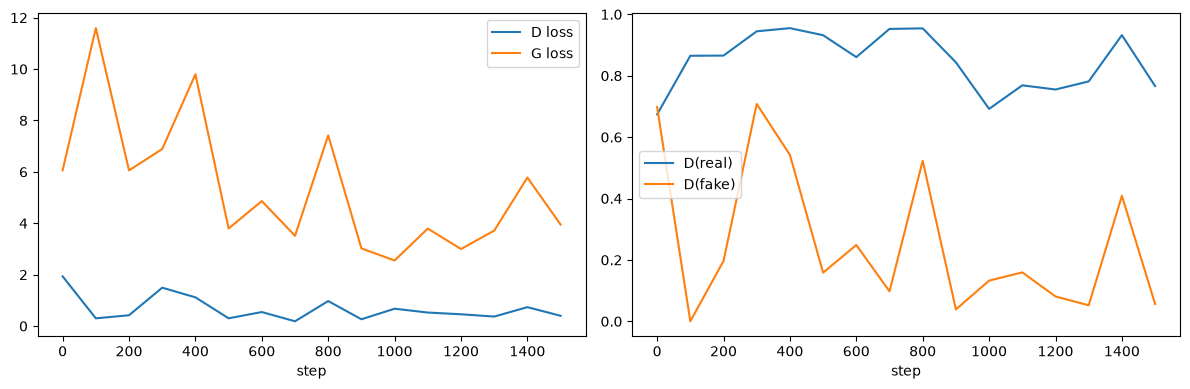

PosixPath('/home/harsh/Work/Notebooks/Projects/Notebooks/artifacts/GAN/baseline/plots/history.png')

In [126]:
save_samples(0, cfg)                  
history = train(cfg, epochs=1)
plot_history(history, cfg)

ep 1/25 step 0 | D 1.710 G 3.443 | D(real) 0.40 D(fake) 0.38
ep 1/25 step 100 | D 0.620 G 7.658 | D(real) 0.90 D(fake) 0.32
ep 1/25 step 200 | D 0.845 G 6.139 | D(real) 0.61 D(fake) 0.02
ep 1/25 step 300 | D 0.529 G 6.162 | D(real) 0.89 D(fake) 0.29
ep 1/25 step 400 | D 0.443 G 5.666 | D(real) 0.88 D(fake) 0.22
ep 1/25 step 500 | D 0.746 G 3.960 | D(real) 0.65 D(fake) 0.04
ep 1/25 step 600 | D 0.374 G 3.711 | D(real) 0.86 D(fake) 0.12
ep 1/25 step 700 | D 1.346 G 4.644 | D(real) 0.41 D(fake) 0.01
ep 1/25 step 800 | D 0.995 G 3.379 | D(real) 0.51 D(fake) 0.01
ep 1/25 step 900 | D 0.218 G 5.480 | D(real) 0.86 D(fake) 0.03
ep 1/25 step 1000 | D 1.042 G 1.458 | D(real) 0.54 D(fake) 0.07
ep 1/25 step 1100 | D 0.433 G 3.829 | D(real) 0.88 D(fake) 0.21
ep 1/25 step 1200 | D 0.393 G 4.167 | D(real) 0.87 D(fake) 0.19
ep 1/25 step 1300 | D 0.524 G 4.605 | D(real) 0.95 D(fake) 0.31
ep 1/25 step 1400 | D 0.836 G 6.176 | D(real) 0.95 D(fake) 0.44
ep 1/25 step 1500 | D 0.520 G 4.820 | D(real) 0.87 D

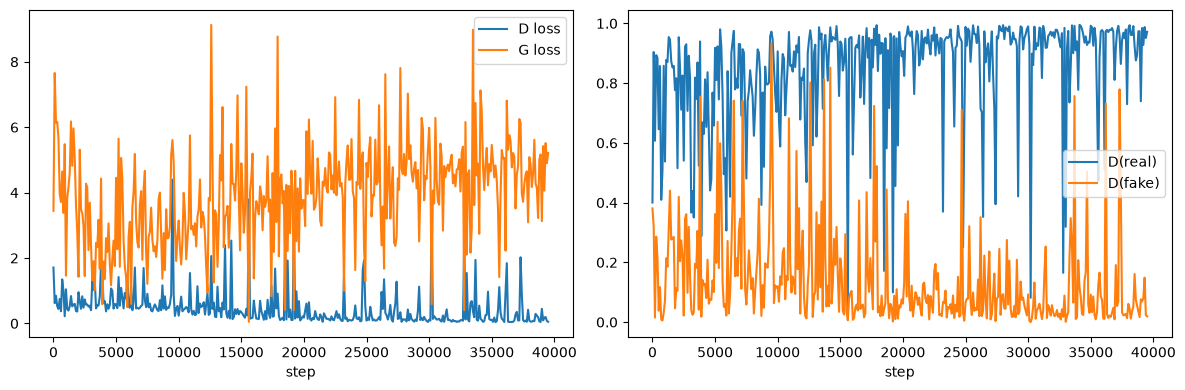

PosixPath('/home/harsh/Work/Notebooks/Projects/Notebooks/artifacts/GAN/baseline_25ep/plots/history.png')

In [128]:
long_cfg = replace(cfg, RUN_NAME="baseline_25ep")
long_cfg.make_dirs(); long_cfg.save()
netG, netD, optG, optD = build(long_cfg)
save_samples(0, long_cfg)
history = train(long_cfg)
plot_history(history, long_cfg)